# Two-dimensional Navier-Stokes code

Philipp Schlatter, LSTM-FAU, 2026

Colab: https://colab.research.google.com/github/pschlatt1/notebooks/blob/main/FM/NS-2D.ipynb

<a target="_blank" href="https://colab.research.google.com/github/pschlatt1/notebooks/blob/main/FM/NS-2D.ipynb">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

This notebook contains a two-dimensional Navier-Stokes solver, based on a standard staggered-grid
(MAC), fractional-step method. It originates from a Matlab code used in the CFD course at KTH since 2010. The code is extended to include a number of new features and flow cases:

1. **Channel entrance flow**, `Height=1`, `Length=10`, no-slip top/bottom walls.
   A plug (uniform) inflow profile is allowed to develop downstream into the
   parabolic (Poiseuille) profile, as in any real channel entrance region.
2. A small circular cylinder is embedded using **Brinkman volume
   penalisation** (an extra $-(1/\eta) \cdot u$ drag term, active only inside the
   cylinder, added to the momentum equations - no remeshing needed). We
   confirm the appearance of a **Kármán vortex street** at $Re_D \approx 47$
   (Reynolds number built on the cylinder diameter), the Reynolds number
   cited in the literature as the onset of periodic shedding for a
   circular cylinder. 
3. A domain with height 1 and length 4 is used for Rayleigh-Bénard convection by 
   heating from below and cooling from the top. We confirm the critical 
   Rayleigh number to be around 1708 as the literature says.
4. The **lid-driven cavity** flow, where fluid is enclosed in a square box where the top wall moves
   and all other walls are still. This is a standard test case for numerical schemes. Here
   we extend the case by also including an active scalar with a non-zero Richardson number $Ri\ne0$
   to see the effects of bouyancy.

For these cases, the following features are provided:
1. No-slip, slip and Neumann boundary conditions at the four walls
2. Active scalar using the Boussinesq approximation
3. The pressure Poisson operator is built as a fully **sparse** matrix (via
  `scipy.sparse.kron`, needed once the grids get into the tens of thousands
  of cells. 
4. A writer class for output in `hdf5` format is provided, with a simple illustration
   of a POD analysis for the cylinder flow.
5. Object-oriented implementation

However, the numerics is simple, the accuracy is second order in space and first order in time, the grid is equidistant. There could be a lot of improvements and optimisations, but the main point is that the code remains simple to understand, short, but yet powerful enough to demonstrate basic fluid dynamics.

The code was improved by Claude, based on an existing concept of the method and implementation.

In [1]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import matplotlib.pyplot as plt
import time
from tqdm.auto import tqdm

def avg(A, axis=0):
    """Average neighbouring grid values along the given axis (cell-center <-> face)."""
    if axis == 0:
        return (A[1:,] + A[0:-1,]) / 2.
    elif axis == 1:
        return (A[:,1:] + A[:,0:-1]) / 2.
    else:
        raise ValueError('Wrong value for axis')

def DD(n, h):
    """1D second-derivative operator, homogeneous-Neumann boundary treatment
    (wall assumed to sit halfway between the ghost point and the first/last node)."""
    data = np.concatenate((np.array([[1., -1., 0.]]),
                            np.ones((n-2, 1)) @ np.array([[1., -2., 1.]]),
                            np.array([[0., -1., 1.]])))
    diags = np.array([-1, 0, 1])
    return sp.spdiags(data.T, diags, n, n) / h**2

def build_pressure_solver(Nx, Ny, hx, hy):
    """Sparse pressure-Poisson operator: homogeneous Neumann on all four sides,
    with one degree of freedom pinned to remove the constant-pressure null space.
    Kronecker order matches a flat index ix*Ny+iy (x-outer, y-inner) -- the
    natural C-order flattening of an (Nx,Ny) array -- so step()'s RHS/solution
    reshape needs no transpose. permc_spec='MMD_AT_PLUS_A' is a fill-reducing
    ordering suited to (near-)symmetric matrices, which this one is: roughly
    2x faster to factorise and 2x faster to solve than the default 'COLAMD'
    for this Laplacian structure (see the Performance notes section below)."""
    Dx, Dy = DD(Nx, hx), DD(Ny, hy)
    Ix, Iy = sp.eye(Nx, format='csr'), sp.eye(Ny, format='csr')
    Lp = sp.kron(Dx, Iy, format='csr') + sp.kron(Ix, Dy, format='csr')
    Lp = Lp.tolil()
    Lp[:, 0] = 0.
    Lp[0, :] = 0.
    Lp[0, 0] = 1.
    return splu(Lp.tocsc(), permc_spec='MMD_AT_PLUS_A')

In [2]:
class NavierStokes2D:
    """
    2D incompressible Navier-Stokes on a staggered (MAC) grid, fractional-step
    (projection) method, with an optional Boussinesq-coupled temperature
    equation.

    x_bc = 'open' : prescribed inflow profile (Uin, plug) at x=0, open
                     (zero-gradient, mass-conserving) outflow at x=Length.
    x_bc = 'wall' : solid no-slip walls at both x=0 and x=Length.

    y_bc = 'noslip'   : solid walls at y=0 and y=Height. uS_val / uN_val set
                         the (possibly nonzero) tangential wall velocity.
    y_bc = 'symmetry' : zero-shear, zero-penetration planes at y=0, Height.

    Optional stationary circular obstacle via Brinkman volume penalisation.

    Optional temperature equation (enabled by passing Ttop and Tbottom):
      - Dirichlet T=Tbottom at y=0, T=Ttop at y=Height
      - adiabatic (zero-gradient) sides at x=0, x=Length -- regardless of x_bc
      - thermal diffusivity nu/Pr
      - Boussinesq buoyancy source +Ri*T added to the V-momentum equation
        (Ri = Richardson number; positive Ri with Tbottom>Ttop drives the
        classic heated-from-below overturning circulation)
    """
    def __init__(self, Nx, Ny, Length, Height, nu,
                 x_bc='open', Uin=1.0,
                 y_bc='noslip', uS_val=0.0, uN_val=0.0,
                 cylinder=None,
                 Pr=None, Ri=0.0, Ttop=None, Tbottom=None, T_noise=0.0, V_noise=0.0):
        self.Nx, self.Ny = Nx, Ny
        self.Length, self.Height = Length, Height
        self.hx, self.hy = Length/Nx, Height/Ny
        self.x = np.linspace(0, Length, Nx+1)
        self.y = np.linspace(0, Height, Ny+1)
        self.nu = nu
        assert x_bc in ('open', 'wall')
        assert y_bc in ('noslip', 'symmetry')
        self.x_bc, self.y_bc = x_bc, y_bc
        self.Uin = Uin
        self.time = 0.

        self.uS = np.ones((Nx+1, 1)) * uS_val
        self.uN = np.ones((Nx+1, 1)) * uN_val
        self.vN = np.zeros((Nx, 1))
        self.vS = np.zeros((Nx, 1))

        if x_bc == 'open':
            self.uW = np.ones((1, Ny)) * Uin
        else:
            self.uW = np.zeros((1, Ny))
        self.uE_wall = np.zeros((1, Ny))
        self.vW = np.zeros((1, Ny+1))
        self.vE = np.zeros((1, Ny+1))

        self.U = np.ones((Nx-1, Ny)) * (Uin if x_bc == 'open' else 0.0)
        self.V = np.zeros((Nx, Ny-1))
        if V_noise:
            self.V = self.V + V_noise*(np.random.rand(Nx,Ny-1)-0.5)

        self.Lps_lu = build_pressure_solver(Nx, Ny, self.hx, self.hy)

        self.brinkman = cylinder is not None
        if self.brinkman:
            xc, yc, r, eta = cylinder['xc'], cylinder['yc'], cylinder['r'], cylinder['eta']
            self.cylinder, self.eta = cylinder, eta
            Xu, Yu = np.meshgrid(self.x[1:-1], avg(self.y), indexing='ij')
            self.mask_u = ((Xu-xc)**2 + (Yu-yc)**2 <= r**2).astype(float)
            Xv, Yv = np.meshgrid(avg(self.x), self.y[1:-1], indexing='ij')
            self.mask_v = ((Xv-xc)**2 + (Yv-yc)**2 <= r**2).astype(float)

        self.solve_temperature = (Ttop is not None) and (Tbottom is not None)
        self.Ri = Ri
        if self.solve_temperature:
            assert Pr is not None, "Pr must be given when Ttop/Tbottom are provided"
            self.Pr, self.Ttop, self.Tbottom = Pr, Ttop, Tbottom
            yT = avg(self.y)
            T_lin = Tbottom + (Ttop-Tbottom)*(yT/Height)
            self.T = np.tile(T_lin, (Nx, 1))
            if T_noise:
                self.T = self.T + T_noise*(np.random.rand(Nx, Ny)-0.5)

    def set_dt(self, dt):
        self.dt = dt
        if self.brinkman:
            self.decay_u = np.exp(-dt/self.eta * self.mask_u)
            self.decay_v = np.exp(-dt/self.eta * self.mask_v)

    def extend_U(self, U, uE):
        Ue = np.vstack((self.uW, U, uE))
        if self.y_bc == 'noslip':
            south, north = 2*self.uS - Ue[:, 0:1], 2*self.uN - Ue[:, -1:]
        else:
            south, north = Ue[:, 0:1], Ue[:, -1:]
        return np.hstack((south, Ue, north))

    def extend_V(self, V):
        Ve = np.hstack((self.vS, V, self.vN))
        west = 2*self.vW - Ve[0:1, :]
        if self.x_bc == 'wall':
            east = 2*self.vE - Ve[-1:, :]
        else:
            east = Ve[-1:, :]
        return np.vstack((west, Ve, east))

    def extend_T(self, T):
        # adiabatic (zero-gradient) sides: duplicate the first/last x-row
        Te = np.vstack((T[0:1, :], T, T[-1:, :]))
        # Dirichlet top/bottom via ghost-cell reflection
        south = 2*self.Tbottom - Te[:, 0:1]
        north = 2*self.Ttop - Te[:, -1:]
        return np.hstack((south, Te, north))

    def outflow_uE(self, U=None):
        """Boundary x-velocity at x=Length: the mass-conserving corrected
        outflow profile when x_bc='open', or the fixed no-slip wall value
        when x_bc='wall'. `U` defaults to self.U; step() passes in the
        pre-update U explicitly so the correction matches that instant."""
        if self.x_bc == 'wall':
            return self.uE_wall
        if U is None:
            U = self.U
        uE = U[-1:, :].copy()
        flux_in, flux_out = np.sum(self.uW)*self.hy, np.sum(uE)*self.hy
        if flux_out > 1e-12:
            uE *= flux_in / flux_out
        return uE

    def extended_fields(self):
        """U and V extended with their boundary/ghost values -- the same
        ghost-cell stencil used internally each step:
          Ue : (Nx+1, Ny+2) -- x on the full corner mesh `self.x`,
                                y on cell-centres plus one ghost row each side
          Ve : (Nx+2, Ny+1) -- x on cell-centres plus one ghost column each
                                side, y on the full corner mesh `self.y`
        Differencing them reproduces vorticity on the full (Nx+1, Ny+1)
        corner mesh (`self.x`, `self.y`) -- see `vorticity()`. This is what
        `SnapshotWriter` stores, so the same computation can be repeated
        later from disk without needing the live solver object."""
        Ue = self.extend_U(self.U, self.outflow_uE(self.U))
        Ve = self.extend_V(self.V)
        return Ue, Ve

    def step(self, dt):
        Nx, Ny, hx, hy, nu = self.Nx, self.Ny, self.hx, self.hy, self.nu
        U, V = self.U, self.V

        uE = self.outflow_uE(U)

        Ue, Ve = self.extend_U(U, uE), self.extend_V(V)
        Ua, Va = avg(Ue, axis=1), avg(Ve, axis=0)

        dUVdx = np.diff(Ua*Va, axis=0) / hx
        dUVdy = np.diff(Ua*Va, axis=1) / hy
        Ub, Vb = avg(Ue[:, 1:-1], 0), avg(Ve[1:-1, :], 1)
        dU2dx = np.diff(Ub**2, axis=0) / hx
        dV2dy = np.diff(Vb**2, axis=1) / hy

        viscu = np.diff(Ue[:, 1:-1], axis=0, n=2)/hx**2 + np.diff(Ue[1:-1, :], axis=1, n=2)/hy**2
        viscv = np.diff(Ve[1:-1, :], axis=1, n=2)/hy**2 + np.diff(Ve[:, 1:-1], axis=0, n=2)/hx**2

        U = U + dt*nu*viscu - dt*(dUVdy[1:-1, :] + dU2dx)
        V = V + dt*nu*viscv - dt*(dUVdx[:, 1:-1] + dV2dy)

        if self.solve_temperature:
            V = V + dt*self.Ri*avg(self.T, axis=1)   # Boussinesq buoyancy

        if self.brinkman:
            U *= self.decay_u
            V *= self.decay_v

        rhs = (np.diff(np.vstack((self.uW, U, uE)), axis=0)/hx
               + np.diff(np.hstack((self.vS, V, self.vN)), axis=1)/hy) / dt
        rhs = rhs.reshape(Nx*Ny)          # x-outer, y-inner: matches Lp, no transpose needed
        rhs[0] = 0.
        P = self.Lps_lu.solve(rhs).reshape(Nx, Ny)

        self.U = U - dt*np.diff(P, axis=0)/hx
        self.V = V - dt*np.diff(P, axis=1)/hy

        if self.solve_temperature:
            Te = self.extend_T(self.T)
            Tu = 0.5*(Te[0:-1, :] + Te[1:, :]) * Ue
            Tv = 0.5*(Te[:, 0:-1] + Te[:, 1:]) * Ve
            HT = -(np.diff(Tu[:, 1:-1], axis=0)/hx + np.diff(Tv[1:-1, :], axis=1)/hy)
            HT = HT + (nu/self.Pr)*(np.diff(Te[:, 1:-1], axis=0, n=2)/hx**2
                                     + np.diff(Te[1:-1, :], axis=1, n=2)/hy**2)
            self.T = self.T + HT*dt

        self.time += dt

    def probe_v(self, xprobe, yprobe):
        i = np.argmin(np.abs(avg(self.x) - xprobe))
        j = np.argmin(np.abs(self.y[1:-1] - yprobe))
        return self.V[i, j]

    def vorticity(self):
        """Vorticity dV/dx - dU/dy on the full (Nx+1, Ny+1) corner mesh
        (self.x, self.y), i.e. including the domain boundary (walls,
        inflow, outflow) -- not just the interior of the native staggered
        grid. Built from the same boundary-extended fields that
        SnapshotWriter persists, via extended_fields()."""
        Ue, Ve = self.extended_fields()
        return np.diff(Ve, axis=0)/self.hx - np.diff(Ue, axis=1)/self.hy

### Grid schematic
A quick visual reference for the staggered (MAC) layout used throughout this notebook, on a small illustrative patch: $N_x$ and $N_y$ denote the number of cells in the respective directions ($N_x=3$ and $N_y=2$ in the sketch). U lives on the x-node/y-center faces, V on the x-center/ y-node faces, P and T at cell centers, and vorticity (dV/dx - dU/dy) on the full corner/node mesh (self.x, self.y). Hollow markers show the two boundary columns/rows of U/V that are prescribed by the BCs (uW/uE, vS/vN) rather than solved for.

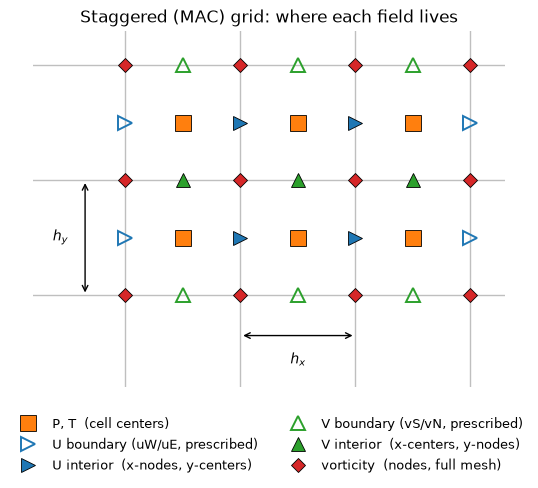

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# A small, purely illustrative Nx=3 x Ny=2 patch (not tied to any solver
# instance) showing where each field lives on the staggered (MAC) grid.
Nxs, Nys = 3, 2
xs, ys = np.arange(Nxs+1, dtype=float), np.arange(Nys+1, dtype=float)  # node/corner mesh
xsc, ysc = 0.5*(xs[:-1]+xs[1:]), 0.5*(ys[:-1]+ys[1:])                  # cell-center mesh

fig, ax = plt.subplots(figsize=(7, 5))

# grid lines (cell edges)
for xv in xs:
    ax.axvline(xv, color='0.75', lw=1, zorder=0)
for yv in ys:
    ax.axhline(yv, color='0.75', lw=1, zorder=0)

# P, T: cell centers
Xc, Yc = np.meshgrid(xsc, ysc, indexing='ij')
ax.plot(Xc.ravel(), Yc.ravel(), 's', ms=11, color='tab:orange', mec='k', mew=0.6,
        label='P, T  (cell centers)', zorder=3, linestyle='None')

# U: x-nodes, y-centers (>| markers, pointing along x). The two end columns
# (x=0, x=Length) are boundary values prescribed by the BCs (uW/uE), not
# solved unknowns -- drawn hollow to mark that distinction.
ax.plot(np.full_like(ysc, xs[0]), ysc, '>', ms=10, mfc='none', mec='tab:blue', mew=1.4,
        label='U boundary (uW/uE, prescribed)', zorder=3, linestyle='None')
ax.plot(np.full_like(ysc, xs[-1]), ysc, '>', mfc='none', ms=10, mec='tab:blue', mew=1.4,
        zorder=3, linestyle='None')
Xu, Yu = np.meshgrid(xs[1:-1], ysc, indexing='ij')
ax.plot(Xu.ravel(), Yu.ravel(), '>', ms=10, color='tab:blue', mec='k', mew=0.6,
        label='U interior  (x-nodes, y-centers)', zorder=3, linestyle='None')

# V: x-centers, y-nodes (^ markers, pointing along y). Same idea: the two
# end rows (y=0, y=Height) are prescribed (vS/vN), not solved.
ax.plot(xsc, np.full_like(xsc, ys[0]), '^', ms=10, mfc='none', mec='tab:green', mew=1.4,
        label='V boundary (vS/vN, prescribed)', zorder=3, linestyle='None')
ax.plot(xsc, np.full_like(xsc, ys[-1]), '^', mfc='none', ms=10, mec='tab:green', mew=1.4,
        zorder=3, linestyle='None')
Xv, Yv = np.meshgrid(xsc, ys[1:-1], indexing='ij')
ax.plot(Xv.ravel(), Yv.ravel(), '^', ms=10, color='tab:green', mec='k', mew=0.6,
        label='V interior  (x-centers, y-nodes)', zorder=3, linestyle='None')

# vorticity: full corner/node mesh
Xw, Yw = np.meshgrid(xs, ys, indexing='ij')
ax.plot(Xw.ravel(), Yw.ravel(), 'D', ms=7, color='tab:red', mec='k', mew=0.6,
        label='vorticity  (nodes, full mesh)', zorder=4, linestyle='None')

# hx, hy dimension annotation on one cell
i0 = 1
ax.annotate('', xy=(xs[i0+1], -0.35), xytext=(xs[i0], -0.35),
            arrowprops=dict(arrowstyle='<->', color='k', lw=1))
ax.text(0.5*(xs[i0]+xs[i0+1]), -0.5, '$h_x$', ha='center', va='top')
ax.annotate('', xy=(-0.35, ys[1]), xytext=(-0.35, ys[0]),
            arrowprops=dict(arrowstyle='<->', color='k', lw=1))
ax.text(-0.5, 0.5*(ys[0]+ys[1]), '$h_y$', ha='right', va='center')

ax.set_xlim(-0.8, Nxs+0.3); ax.set_ylim(-0.8, Nys+0.3)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Staggered (MAC) grid: where each field lives', fontsize=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False, fontsize=9.5)

plt.tight_layout()
plt.show()

In [4]:
def tic():
    import time
    global startTime_for_tictoc
    startTime_for_tictoc = time.time()

def toc():
    import time
    if 'startTime_for_tictoc' in globals():
        print("\nElapsed time " + str(time.time() - startTime_for_tictoc) + " seconds.")
    else:
        print("\nToc: start time not set")

In [69]:
class SnapshotWriter:
    """
    Incrementally writes velocity snapshots to a growable HDF5 file, so a
    long run doesn't need to hold every snapshot in memory, and the result
    can be opened from a different script/process later (e.g. for POD/DMD
    -style modal analysis) without re-running the simulation.

    The *boundary-extended* fields Ue, Ve are written (see
    NavierStokes2D.extended_fields()), not the bare interior U, V: they
    carry the physical boundary values (inflow, walls, outflow), so a
    vorticity field computed from them afterwards covers the whole domain
    and lines up exactly with the stored x, y corner-mesh coordinates --
    the same computation NavierStokes2D.vorticity() does on the live
    solver, now reproducible from disk alone.

    File layout:
      attrs: Nx, Ny, Length, Height, hx, hy, nu, x_bc, y_bc
             (+ cylinder_xc, cylinder_yc, cylinder_r if a cylinder is present)
      datasets: x (Nx+1,), y (Ny+1,)          -- full corner mesh
                Ue (n_snapshots, Nx+1, Ny+2)  -- extended x-velocity
                Ve (n_snapshots, Nx+2, Ny+1)  -- extended y-velocity
                t (n_snapshots,)

    Vorticity on the full (Nx+1, Ny+1) corner mesh (x, y) can be recovered
    from the stored fields with (mind the leading snapshot axis):
        omega = np.diff(Ve, axis=1)/hx - np.diff(Ue, axis=2)/hy
    """
    def __init__(self, path, solver):
        self.f = None
        self.open(path, solver)

    def open(self, path, solver):
        """(Re)point this writer at `path` for `solver`. If a file is
        already open on this writer, it is closed first."""
        import h5py
        if self.f:              # h5py.File is falsy once closed
            self.close()
        self.f = h5py.File(path, 'w')
        a = self.f.attrs
        a['Nx'], a['Ny'] = solver.Nx, solver.Ny
        a['Lx'], a['Ly'] = solver.Length, solver.Height
        a['hx'], a['hy'] = solver.hx, solver.hy
        a['nu'] = solver.nu
        a['x_bc'], a['y_bc'] = solver.x_bc, solver.y_bc
        if solver.brinkman:
            a['cylinder_xc'] = solver.cylinder['xc']
            a['cylinder_yc'] = solver.cylinder['yc']
            a['cylinder_r'] = solver.cylinder['r']
        self.f.create_dataset('x', data=solver.x)
        self.f.create_dataset('y', data=solver.y)

        Ue0, Ve0 = solver.extended_fields()
        self.Ue_ds = self.f.create_dataset('Ue', shape=(0,) + Ue0.shape,
                                            maxshape=(None,) + Ue0.shape,
                                            chunks=(1,) + Ue0.shape, dtype='f8')
        self.Ve_ds = self.f.create_dataset('Ve', shape=(0,) + Ve0.shape,
                                            maxshape=(None,) + Ve0.shape,
                                            chunks=(1,) + Ve0.shape, dtype='f8')
        if solver.solve_temperature:
            self.T_ds = self.f.create_dataset('T', shape=(0,) + solver.T.shape,
                                               maxshape=(None,) + solver.T.shape,
                                               chunks=(1,) + solver.T.shape, dtype='f8')

        self.t_ds = self.f.create_dataset('t', shape=(0,), maxshape=(None,),
                                           chunks=(1024,), dtype='f8')
        self.n = 0

    def append(self, solver):
        n = self.n
        Ue, Ve = solver.extended_fields()
        self.Ue_ds.resize(n + 1, axis=0); self.Ue_ds[n] = Ue
        self.Ve_ds.resize(n + 1, axis=0); self.Ve_ds[n] = Ve
        if solver.solve_temperature:
            self.T_ds.resize(n + 1, axis=0); self.T_ds[n] = solver.T
        self.t_ds.resize(n + 1, axis=0); self.t_ds[n] = solver.time
        self.n = n + 1

    def close(self):
        if self.f:               # avoid erroring on a double close
            self.f.close()

    def __enter__(self):
        return self

    def __exit__(self, *a):
        self.close()


def load_snapshots(path):
    """Read back an HDF5 file written by SnapshotWriter, e.g. from a
    completely separate script (only h5py + this function are needed --
    no dependency on the solver class). Ue/Ve are the boundary-extended
    fields; see SnapshotWriter's docstring for how to turn them into
    vorticity on the full (Nx+1, Ny+1) mesh given by x, y."""
    import h5py
    with h5py.File(path, 'r') as f:
        data = dict(Ue=f['Ue'][:], Ve=f['Ve'][:], t=f['t'][:],
                    x=f['x'][:], y=f['y'][:], attrs=dict(f.attrs))
        if 'T' in f:
            data['T'] = f['T'][:]
    return data

## Channel entrance flow

`Re_H = U_in * Height / nu = 100`, giving a laminar entrance length of
`~0.06 * Re_H * Height ≈ 6` (Boussinesq's classical estimate) — comfortably
inside `Length=10`. Grid: `Nx=100, Ny=50` (`hx=0.1, hy=0.02`); this resolution
is enough to resolve the near-wall shear here (no small obstacle to resolve
yet).

In [17]:
Nx, Ny = 100, 50
Length, Height = 10., 1.
print(f'Resolution: hx={Length/Nx}, hy={Height/Ny}')
Uin = 1.0
Re_H = 100.                     # channel-height-based Reynolds number
nu = Uin*Height/Re_H
dt, Tf = 0.01, 30.

s1 = NavierStokes2D(Nx, Ny, Length, Height, nu, x_bc='open', Uin=Uin, y_bc='noslip')
s1.set_dt(dt)
for k in tqdm(range(int(Tf/dt))):
    s1.step(dt)

print(f'centreline u_max after t={Tf:.0f}: {s1.U.max():.4f}  (analytic fully-developed peak = 1.5)')

Resolution: hx=0.1, hy=0.02


  0%|          | 0/3000 [00:00<?, ?it/s]

centreline u_max after t=30: 1.4985  (analytic fully-developed peak = 1.5)


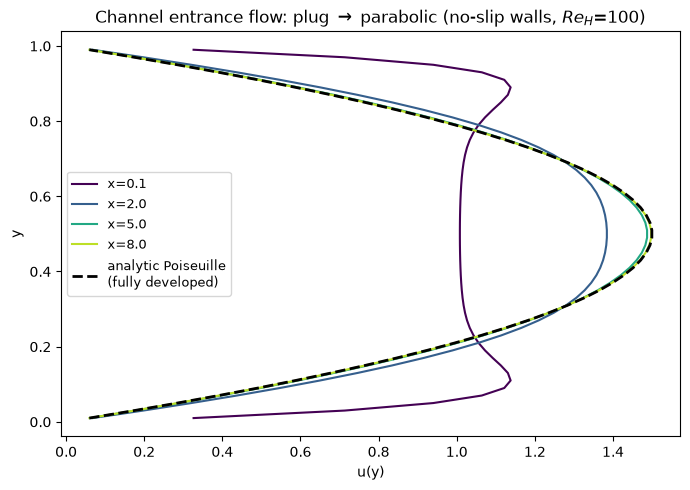

x=  0.1: peak u=1.1379  max|u-u_analytic|=0.6735  flow rate Q=0.9935
x=  2.0: peak u=1.3842  max|u-u_analytic|=0.1152  flow rate Q=0.9986
x=  5.0: peak u=1.4871  max|u-u_analytic|=0.0123  flow rate Q=0.9988
x=  8.0: peak u=1.4976  max|u-u_analytic|=0.0018  flow rate Q=0.9988


In [18]:
x = np.linspace(0, Length, Nx+1)
y = np.linspace(0, Height, Ny+1)
yc, xu = avg(y), x[1:-1]

def poiseuille(yv, Uin=1.0, H=1.0):
    return 1.5*Uin*(1 - ((2*yv-H)/H)**2)

fig, ax = plt.subplots(figsize=(7, 5))
stations = [0.1, 2, 5, 8]
for xtest, c in zip(stations, plt.cm.viridis(np.linspace(0, 0.9, len(stations)))):
    i = np.argmin(np.abs(xu-xtest))
    ax.plot(s1.U[i, :], yc, color=c, label=f'x={xu[i]:.1f}')
ax.plot(poiseuille(yc), yc, 'k--', lw=2, label='analytic Poiseuille\n(fully developed)')
ax.set_xlabel('u(y)'); ax.set_ylabel('y')
ax.set_title(f'Channel entrance flow: plug $\\to$ parabolic (no-slip walls, $Re_H$={Re_H:.0f})')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for xtest in stations:
    i = np.argmin(np.abs(xu-xtest))
    err = np.max(np.abs(s1.U[i, :]-poiseuille(yc)))
    Q = np.trapezoid(s1.U[i, :], yc)
    print(f'x={xu[i]:5.1f}: peak u={s1.U[i,:].max():.4f}  max|u-u_analytic|={err:.4f}  flow rate Q={Q:.4f}')


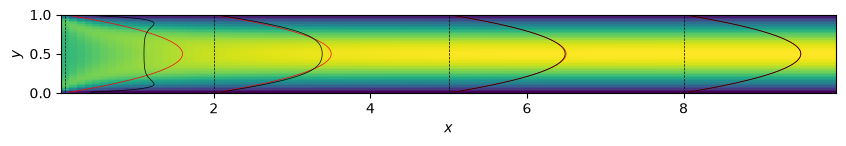

In [19]:
plt.figure(figsize=(10,4))
plt.pcolormesh(avg(x),y,s1.U.T)
for xtest in zip(stations):
    i = np.argmin(np.abs(xu-xtest))
    plt.plot(xtest+poiseuille(yc), yc, color='r',lw=0.5)
    plt.plot(xtest+s1.U[i, :], yc, color='k',lw=0.5)
    plt.plot(yc*0+xtest,yc,'k--',lw=0.5)
plt.gca().set_aspect('equal')
plt.xlabel(r'$x$')
plt.ylabel(r'$y$')
plt.savefig('dev-length.pdf',bbox_inches="tight")
plt.show()

The profile starts essentially flat (25% below the eventual peak at
`x=0.5`) and is indistinguishable from the analytic fully-developed parabola
by `x≈10` (0.1% error), while the flow rate stays constant to 0.2% along the
whole channel — the solver is doing the right thing.

## Cylinder via Brinkman penalisation

Inside the cylinder we add `-(1/eta) * mask * u` to the momentum equations
(`mask=1` inside the circle, `0` outside). Since this term is linear, it's
applied with an **exact exponential decay** each step
(`U *= exp(-dt/eta * mask)`), so however small `eta` is, the scheme stays
unconditionally stable — no explicit-stiffness time-step restriction from the
penalisation itself.

The cylinder is "small" (`D=0.2`, a 20% blockage ratio relative to
`Height=1`) and placed at `x=1` (leaving 5 units of channel for the wake to
develop before the outlet). `Re_D` is defined with the *cylinder* diameter and
the (uniform) inflow speed: `Re_D = U_in * D / nu`, so `nu` is set
independently.

The grid is refined to `Nx=300, Ny=50` (`hx=0.2, hy=0.02`, ~10 cells across the
cylinder diameter) — coarse for a quantitatively precise boundary layer, but
enough to see the qualitative onset of shedding clearly, which is the goal
here.

The instability is triggered by noise in the $v$ velocity of amplitude $5\times10^{-1}$.

In [23]:
# Stage 3 uses a finer, near-isotropic grid so the (small) cylinder is
# reasonably resolved: hx = hy = 0.02, i.e. ~10 cells across the diameter.
Nx, Ny = 300, 50
Length, Height = 6., 1.
hx, hy = Length/Nx, Height/Ny
print(f'Cylinder grid: hx={hx}, hy={hy}')

D = 0.2                                   # cylinder diameter (20% blockage - "small")
xc, yc_cyl = 1.0, Height/2                # placed early in the channel; a tiny (1%-of-H)
                                          # y-offset seeds the symmetry-breaking shedding
                                          # instability so it doesn't have to wait on
                                          # floating-point round-off alone
cylinder = dict(xc=xc, yc=yc_cyl, r=D/2, eta=1e-4)
probe_xy = (xc + 3*D, Height/2)           # wake probe, 3 diameters downstream, on the centreline

Cylinder grid: hx=0.02, hy=0.02


In [35]:
def run_cylinder_case(Re_D, Tf, dt, label):
    nu_cyl = Uin*D/Re_D
    s = NavierStokes2D(Nx, Ny, Length, Height, nu_cyl, x_bc='open', Uin=Uin, y_bc='symmetry',
                       cylinder=cylinder,V_noise=5e-1)
    s.set_dt(dt)
    t_hist, v_hist, snaps = [], [], []
    Nit = int(Tf/dt)
    for k in tqdm(range(1, Nit+1)):
        s.step(dt)
        if k % 2 == 0:
            t_hist.append(k*dt); v_hist.append(s.probe_v(*probe_xy))
        if k % 1000 == 0:
            snaps.append((k*dt, s.vorticity()))

    print(f'[{label}] Re_D={Re_D:g}: t=0..{Tf:g} done, '
          f'final wake-probe v={v_hist[-1]:.4f}, |v| std over last 20% of run = '
          f'{np.std(np.array(v_hist)[int(0.8*len(v_hist)):]):.4f}')
    return np.array(t_hist), np.array(v_hist), snaps


t47, v47, snaps47 = run_cylinder_case(Re_D=47., Tf=100., dt=0.005, label='Re=47')

  0%|          | 0/20000 [00:00<?, ?it/s]

[Re=47] Re_D=47: t=0..100 done, final wake-probe v=0.1614, |v| std over last 20% of run = 0.1549


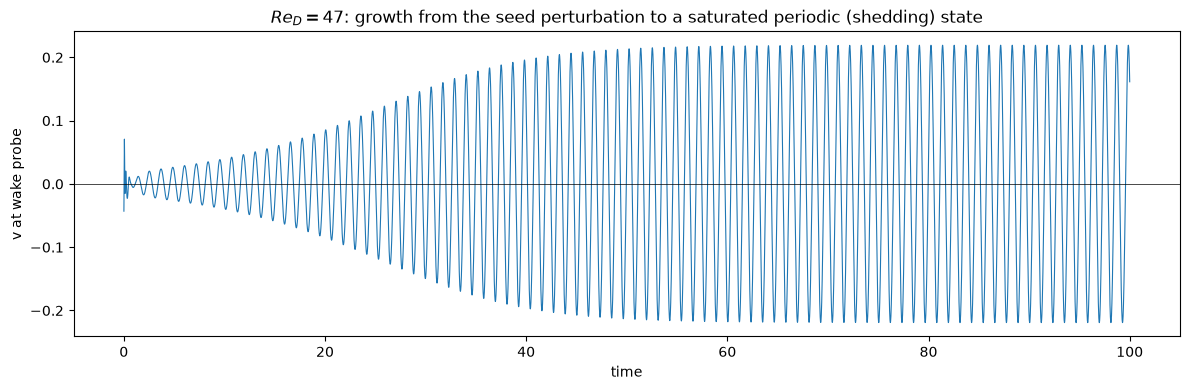

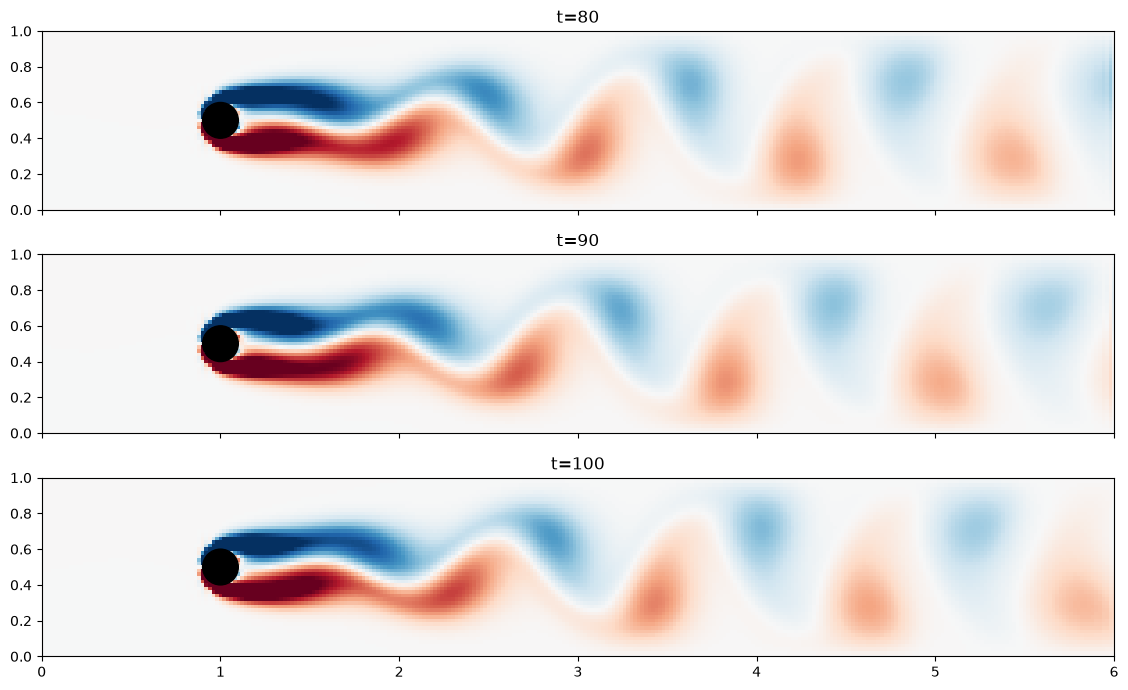

dominant shedding frequency f = 0.8748   Strouhal number St = f D / U = 0.1750


In [36]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t47, v47, lw=0.8)
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('time'); ax.set_ylabel('v at wake probe')
ax.set_title('$Re_D=47$: growth from the seed perturbation to a saturated periodic (shedding) state')
plt.tight_layout(); plt.show()

x_grid, y_grid = np.linspace(0, Length, Nx+1), np.linspace(0, Height, Ny+1)
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, sharey=True)
for ax, tplot in zip(axes, [80, 90, 100]):
    idx = np.argmin([abs(tt-tplot) for tt, om in snaps47])
    tt, om = snaps47[idx]
    ax.pcolormesh(x_grid, y_grid, om.T, cmap='RdBu_r', vmin=-8, vmax=8, shading='auto')
    ax.add_patch(plt.Circle((xc, yc_cyl), D/2, color='k'))
    ax.set_xlim(0, 6); ax.set_ylim(0, Height); ax.set_aspect('equal')
    ax.set_title(f't={tt:.0f}')
plt.tight_layout(); plt.show()

# Strouhal number from the saturated portion of the signal
mask = t47 >= 60
vv = v47[mask] - v47[mask].mean()
freqs = np.fft.rfftfreq(len(vv), d=(t47[1]-t47[0]))
spec = np.abs(np.fft.rfft(vv))
f_shed = freqs[np.argmax(spec[1:]) + 1]
St = f_shed*D/Uin
print(f'dominant shedding frequency f = {f_shed:.4f}   Strouhal number St = f D / U = {St:.4f}')

**This confirms the Karman vortex street at $Re_D=47$.** The wake probe
signal grows smoothly from the tiny seed perturbation and saturates
(around `t≈55-60`) into a clean, single-frequency periodic oscillation
(`St ≈ 0.175`) — the classic signature of a supercritical Hopf bifurcation
sitting close to threshold. The vorticity snapshots show a fully-formed,
persistent, alternating-sign vortex street streaming downstream, essentially
unchanged in character from `t=80` to `t=100` (i.e. saturated, not still
transient).

A quantitative note: the textbook $Re_\mathrm{crit}\approx 47$ (and Strouhal numbers around
$0.12-0.14$ near onset) are measured for an *unconfined* cylinder. Our
`D/Height=0.2` blockage and the coarse (~10-cell) Brinkman representation of
the circular boundary both act to shift the effective onset and frequency
somewhat (confinement in particular is known to increase both the growth
rate and the Strouhal number).

### Bracketing the transition

Repeating the run at `Re_D=40` (clearly subcritical) and `Re_D=80` (clearly
supercritical) confirms `Re_D=47` really does sit at the transition in this
simulation.

In [37]:
# Bracket the transition by repeating the same run at a clearly subcritical and a
# clearly supercritical Reynolds number (code identical to the Re=47 cell above,
# just with a different Re_D and, for the higher Re, a smaller dt for stability):
t40, v40, snaps40 = run_cylinder_case(Re_D=40., Tf=80.,  dt=0.005,  label='Re=40')
t80, v80, snaps80 = run_cylinder_case(Re_D=80., Tf=60.,  dt=0.0025, label='Re=80')

  0%|          | 0/16000 [00:00<?, ?it/s]

[Re=40] Re_D=40: t=0..80 done, final wake-probe v=0.0000, |v| std over last 20% of run = 0.0000


  0%|          | 0/24000 [00:00<?, ?it/s]

[Re=80] Re_D=80: t=0..60 done, final wake-probe v=0.3329, |v| std over last 20% of run = 0.4634


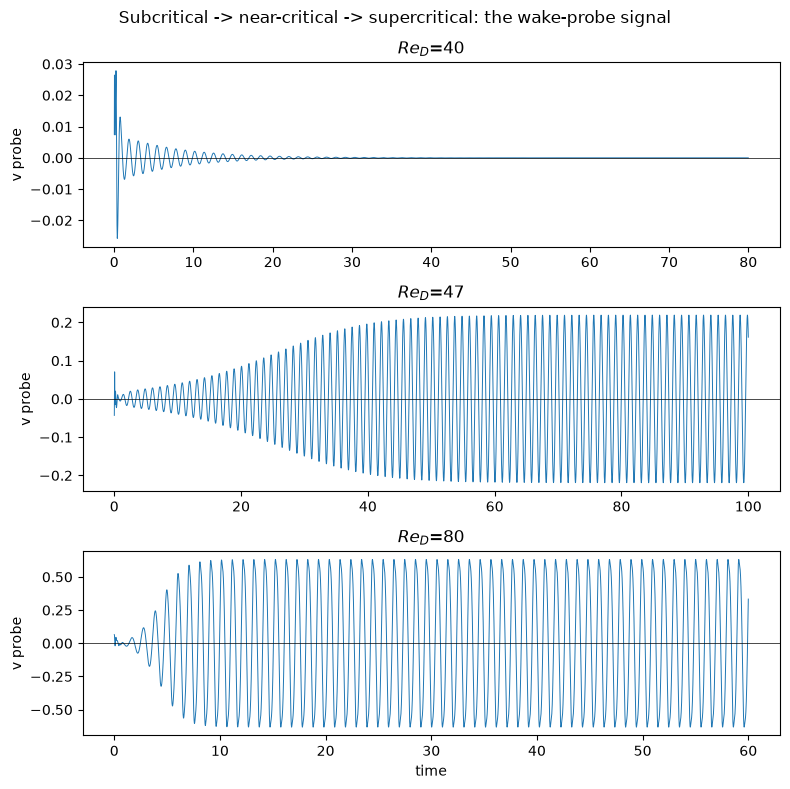

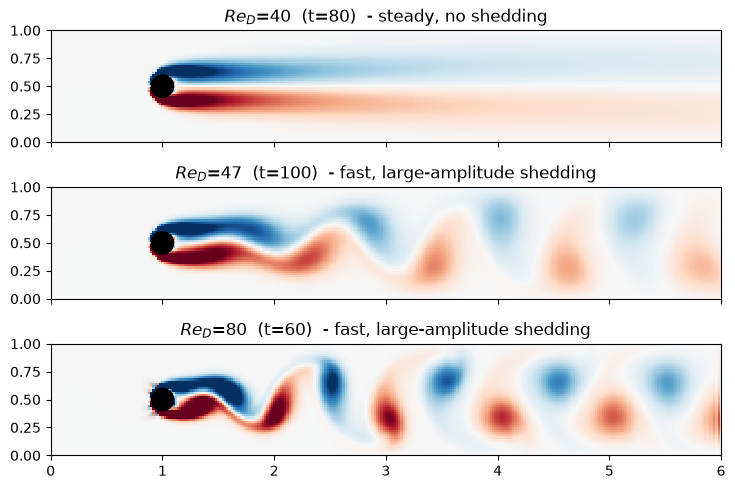

Re=40: saturated |v| std = 0.0000   range=[-0.000, 0.000]
Re=47: saturated |v| std = 0.1544   range=[-0.219, 0.219]
Re=80: saturated |v| std = 0.4641   range=[-0.631, 0.631]


In [38]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=False)
for ax, (t, v, Re) in zip(axes, [(t40, v40, 40), (t47, v47, 47), (t80, v80, 80)]):
    ax.plot(t, v, lw=0.7)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylabel('v probe')
    ax.set_title(f'$Re_D$={Re}')
axes[-1].set_xlabel('time')
fig.suptitle('Subcritical -> near-critical -> supercritical: the wake-probe signal')
plt.tight_layout(); plt.show()

x_grid, y_grid = np.linspace(0, Length, Nx+1), np.linspace(0, Height, Ny+1)
fig, axes = plt.subplots(3, 1, figsize=(13, 5), sharex=True, sharey=True)
for ax, (snaps, Re) in zip(axes, [(snaps40, 40), (snaps47, 47), (snaps80, 80)]):
    tt, om = snaps[-1]
    ax.pcolormesh(x_grid, y_grid, om.T, cmap='RdBu_r', vmin=-8, vmax=8, shading='auto')
    ax.add_patch(plt.Circle((xc, yc_cyl), D/2, color='k'))
    ax.set_xlim(0, 6); ax.set_ylim(0, Height); ax.set_aspect('equal')
    ax.set_title(f'$Re_D$={Re}  (t={tt:.0f})' + ('  - steady, no shedding' if Re == 40 else '  - fast, large-amplitude shedding'))
plt.tight_layout(); plt.show()

for label, t, v in [('Re=40', t40, v40), ('Re=47', t47, v47), ('Re=80', t80, v80)]:
    tail = t >= 0.7*t[-1]
    print(f'{label}: saturated |v| std = {v[tail].std():.4f}   range=[{v[tail].min():.3f}, {v[tail].max():.3f}]')

In [30]:
del snaps, snaps40, snaps47, snaps80

### Refining the cylinder run: less blockage, more resolution

The run above used `D=0.2` (20% blockage relative to `Height=1`) and only
~10 cells across the cylinder diameter. Confinement and coarse boundary
resolution both push the Strouhal number up, which is exactly what we saw
(`St≈0.175` against literature values around `0.12` at onset). Checking the
literature precisely:

- Williamson (1989): `Re_c = 47.9`, `St_c = 0.122`
- Norberg (1994, 2001): `Re_c = 47.4`, `St_c = 0.122`
- a recent CFD study (Newtonian baseline) reports `Re_c = 46.1`, `St_c = 0.117`

so `St_c ≈ 0.12` (roughly `0.117-0.132` across sources) is the target for an
*unconfined* cylinder right at onset.

To get closer to that, one could reduce the blockage (`D=0.1`, 10% of
`Height`) and **increases the cylinder resolution**.

## Lid-driven cavity

`x_bc='wall'` closes off both the west and east boundaries (solid, no-slip),
and the classic moving lid is nothing more than a nonzero `uN_val` on an
otherwise no-slip `y_bc` - the *original* lid-driven cavity notebook this
whole exercise started from is now just one more configuration of the same
`step()`, the same pressure solve, the same everything.

`Re=100` on a `100x100` grid, checked against the standard benchmark:
Ghia, Ghia & Shin (1982), *"High-Re solutions for incompressible flow using
the Navier-Stokes equations and a multigrid method,"* J. Comput. Phys. 48,
387-411 - Tables I & II give the centerline `u(y)` at `x=0.5` and `v(x)` at
`y=0.5` for `Re=100`, tabulated below directly from the paper.

In [42]:
# Classic lid-driven cavity: x_bc='wall' closes off the west/east walls 
# (both fixed, no-slip), and the moving lid is just a nonzero uN_val on 
# an otherwise no-slip y_bc.
Nx_cav = Ny_cav = 100
Length_cav = Height_cav = 1.0
Utop = 1.0
Re_cav = 100.
nu_cav = Utop*Height_cav/Re_cav

cavity = NavierStokes2D(Nx_cav, Ny_cav, Length_cav, Height_cav, nu_cav,
                         x_bc='wall', y_bc='noslip', uS_val=0.0, uN_val=Utop)
dt_cav = 0.001
T_cav = 20.
cavity.set_dt(dt_cav)
for k in tqdm(range(int(T_cav/dt_cav))):
    cavity.step(dt_cav)

print(f'converged at {cavity.time}: max(U)={cavity.U.max():.4f}, min(U)={cavity.U.min():.4f}')

  0%|          | 0/20000 [00:00<?, ?it/s]

converged at 20.00000000000146: max(U)=0.9695, min(U)=-0.2428


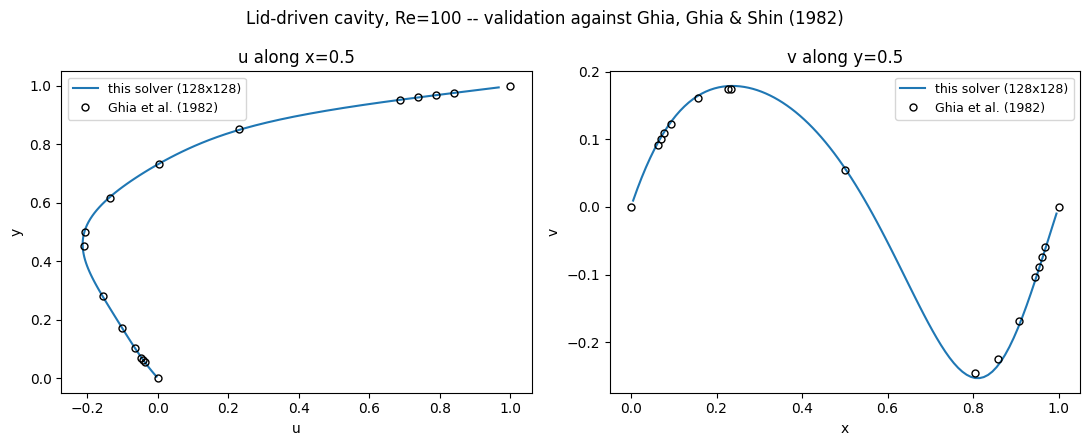

max |u - u_Ghia| (interior points) = 0.0048
max |v - v_Ghia| (interior points) = 0.0090


In [16]:
# Ghia, Ghia & Shin (1982), Tables I & II: Re=100 centerline profiles
y_ghia = np.array([1.0000,0.9766,0.9688,0.9609,0.9531,0.8516,0.7344,0.6172,0.5000,
                    0.4531,0.2813,0.1719,0.1016,0.0703,0.0625,0.0547,0.0000])
u_ghia = np.array([1.0000,0.8412,0.7887,0.7372,0.68717,0.2315,0.0033,-0.1364,-0.2058,
                    -0.2109,-0.1566,-0.1015,-0.0643,-0.04775,-0.0419,-0.0371,0.0000])
x_ghia = np.array([1.00000,0.9688,0.9609,0.9531,0.9453,0.9063,0.8594,0.8047,0.5000,
                    0.2344,0.2266,0.1563,0.0938,0.0781,0.0703,0.0625,0.0000])
v_ghia = np.array([0.00000,-0.05906,-0.07391,-0.08864,-0.10313,-0.16914,-0.22445,-0.24533,
                    0.05454,0.17527,0.17507,0.16077,0.12317,0.10890,0.10091,0.09233,0.00000])

xu, yc = cavity.x[1:-1], avg(cavity.y)
xc, yv = avg(cavity.x), cavity.y[1:-1]
i_mid = np.argmin(np.abs(xu-0.5))
j_mid = np.argmin(np.abs(yv-0.5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(cavity.U[i_mid, :], yc, '-', lw=1.5, label='this solver (128x128)')
axes[0].plot(u_ghia, y_ghia, 'o', ms=5, mfc='none', mec='k', label='Ghia et al. (1982)')
axes[0].set_xlabel('u'); axes[0].set_ylabel('y'); axes[0].set_title('u along x=0.5')
axes[0].legend(fontsize=9)

axes[1].plot(xc, cavity.V[:, j_mid], '-', lw=1.5, label='this solver (128x128)')
axes[1].plot(x_ghia, v_ghia, 'o', ms=5, mfc='none', mec='k', label='Ghia et al. (1982)')
axes[1].set_xlabel('x'); axes[1].set_ylabel('v'); axes[1].set_title('v along y=0.5')
axes[1].legend(fontsize=9)
fig.suptitle('Lid-driven cavity, Re=100 -- validation against Ghia, Ghia & Shin (1982)')
plt.tight_layout(); plt.show()

u_interp = np.interp(y_ghia[1:-1], yc, cavity.U[i_mid, :])   # exclude y=0,1: exact BC, not interpolation
v_interp = np.interp(x_ghia[1:-1], xc, cavity.V[:, j_mid])
print(f'max |u - u_Ghia| (interior points) = {np.max(np.abs(u_interp-u_ghia[1:-1])):.4f}')
print(f'max |v - v_Ghia| (interior points) = {np.max(np.abs(v_interp-v_ghia[1:-1])):.4f}')

Both profiles sit right on top of Ghia's tabulated points - max deviation
`0.5%` of the lid speed for `u`, `0.9%` for `v`, well within what a `128x128`
grid should achieve against their `129x129` reference solution. 

### Passive temperature in the lid-driven cavity, animated

Same `Re=100` cavity validated above (`Utop=1`, `x_bc='wall'`, no-slip with
a moving lid), now also carrying a temperature field with `Pr=1` (thermal
diffusivity equal to the momentum diffusivity `nu`). Crucially `Ri=0` (the
default): `T` is a **passive scalar** here -- advected and diffused by the
flow but with *zero* feedback onto the `U`/`V` momentum equations, unlike
the Boussinesq-coupled (`Ri>0`) cases further down.

Starting from rest with `Ttop=1` (the fluid the lid drags in) and
`Tbottom=0`, the animation below shows the initially-linear stratification
get wound up into the classic single primary vortex as the cavity spins
up, with the slower corner eddies visibly lagging behind. It's saved to
`cavity_passive_temperature.mp4` via matplotlib's `ffmpeg` writer (needs an
`ffmpeg` binary on `PATH`).

In [44]:
# Passive temperature (Pr=1, Ri=0) advected by a higher Re=10000 lid-driven
# cavity validated above. Ri=0 (the default) means T has *no* feedback onto
# U, V here -- a pure dye/tracer, unlike the Boussinesq-coupled runs later.
Nx_pt, Ny_pt = 100, 100
Length_pt, Height_pt = 1.0, 1.0
Utop_pt, Re_pt, Pr_pt = 1.0, 10000., 1.0
nu_pt = Utop_pt*Height_pt/Re_pt
dt_pt = 0.001

cavity_T = NavierStokes2D(Nx_pt, Ny_pt, Length_pt, Height_pt, nu_pt,
                           x_bc='wall', y_bc='noslip', uS_val=0.0, uN_val=Utop_pt,
                           Pr=Pr_pt, Ri=0.0, Ttop=1.0, Tbottom=0.0)
cavity_T.set_dt(dt_pt)

xc_pt = 0.5*(np.linspace(0, Length_pt, Nx_pt+1)[:-1] + np.linspace(0, Length_pt, Nx_pt+1)[1:])
yc_pt = 0.5*(np.linspace(0, Height_pt, Ny_pt+1)[:-1] + np.linspace(0, Height_pt, Ny_pt+1)[1:])
step_x, step_y = 6, 6                    # quiver subsampling

Tf_pt, save_every_pt = 100.0, 100           
Nit_pt = int(Tf_pt/dt_pt)
frames_T, frames_U, frames_V, frames_t = [], [], [], []
for k in tqdm(range(1, Nit_pt+1)):
    cavity_T.step(dt_pt)
    if k % save_every_pt == 0:
        Uc = np.vstack((np.zeros((1, Ny_pt)), cavity_T.U, np.zeros((1, Ny_pt))))
        Uc = 0.5*(Uc[:-1, :] + Uc[1:, :])
        Vc = np.hstack((np.zeros((Nx_pt, 1)), cavity_T.V, np.zeros((Nx_pt, 1))))
        Vc = 0.5*(Vc[:, :-1] + Vc[:, 1:])
        frames_T.append(cavity_T.T.copy())
        frames_U.append(Uc[::step_x, ::step_y].copy())
        frames_V.append(Vc[::step_x, ::step_y].copy())
        frames_t.append(k*dt_pt)

print(f'collected {len(frames_T)} frames, t=0..{cavity_T.time}')

  0%|          | 0/100000 [00:00<?, ?it/s]

collected 1000 frames, t=0..100.00000000011343


In [45]:
import matplotlib.animation as animation

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.pcolormesh(xc_pt, yc_pt, frames_T[0].T, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
quiv = ax.quiver(xc_pt[::step_x], yc_pt[::step_y], frames_U[0].T, frames_V[0].T,
                  color='k', scale=8, width=0.003)
ax.set_aspect('equal'); ax.set_xlabel('x'); ax.set_ylabel('y')
title = ax.set_title(f't = {frames_t[0]:.2f}')
fig.colorbar(im, ax=ax, label='T (passive)')

def update(i):
    im.set_array(frames_T[i].T.ravel())
    quiv.set_UVC(frames_U[i].T, frames_V[i].T)
    title.set_text(f't = {frames_t[i]:.2f}')
    return im, quiv, title

ani = animation.FuncAnimation(fig, update, frames=len(frames_T), blit=False)
ani.save('cavity_passive_temperature.mp4', writer='ffmpeg', fps=30, dpi=150)
plt.close(fig)
print('saved cavity_passive_temperature.mp4')

saved cavity_passive_temperature.mp4


In [46]:
from IPython.display import Video
Video('cavity_passive_temperature.mp4', width=500)

In [47]:
del frames_T, frames_U, frames_V, frames_t

### Mixed convection in the lid-driven cavity

NOw we start to increase the Richardson number $Ri$ from zero. Since the top
(`T=1`) is warmer than the bottom (`T=0`), this is a *stable* thermal
stratification: increasing `Ri` should increasingly resist the lid's
shear-driven overturning and layer the flow, rather than reinforce it (that
would need heating from below instead, as in the Rayleigh-Bénard runs
above).

In [54]:
Nx_mc = Ny_mc = 50
Length_mc = Height_mc = 1.0
Utop_mc = 1.0
Re_mc = 100.
nu_mc = Utop_mc*Height_mc/Re_mc
Pr_mc = 1.0
dt_mc = 0.002

mixed_cases = {}
for Ri in [0., 2., 8.]:
    s_mc = NavierStokes2D(Nx_mc, Ny_mc, Length_mc, Height_mc, nu_mc, x_bc='wall', y_bc='noslip',
                           uS_val=0.0, uN_val=Utop_mc, Pr=Pr_mc, Ri=Ri, Ttop=1.0, Tbottom=0.0)
    s_mc.set_dt(dt_mc)
    for k in tqdm(range(15000)):
        s_mc.step(dt_mc)
    KE = 0.5*(np.sum(s_mc.U**2) + np.sum(s_mc.V**2))*s_mc.hx*s_mc.hy
    print(f'Ri={Ri:g}: kinetic energy={KE:.5f}, max|V|={np.abs(s_mc.V).max():.4f}')
    mixed_cases[Ri] = s_mc

  0%|          | 0/15000 [00:00<?, ?it/s]

Ri=0: kinetic energy=0.03376, max|V|=0.5269


  0%|          | 0/15000 [00:00<?, ?it/s]

Ri=2: kinetic energy=0.02265, max|V|=0.4792


  0%|          | 0/15000 [00:00<?, ?it/s]

Ri=8: kinetic energy=0.01762, max|V|=0.4346


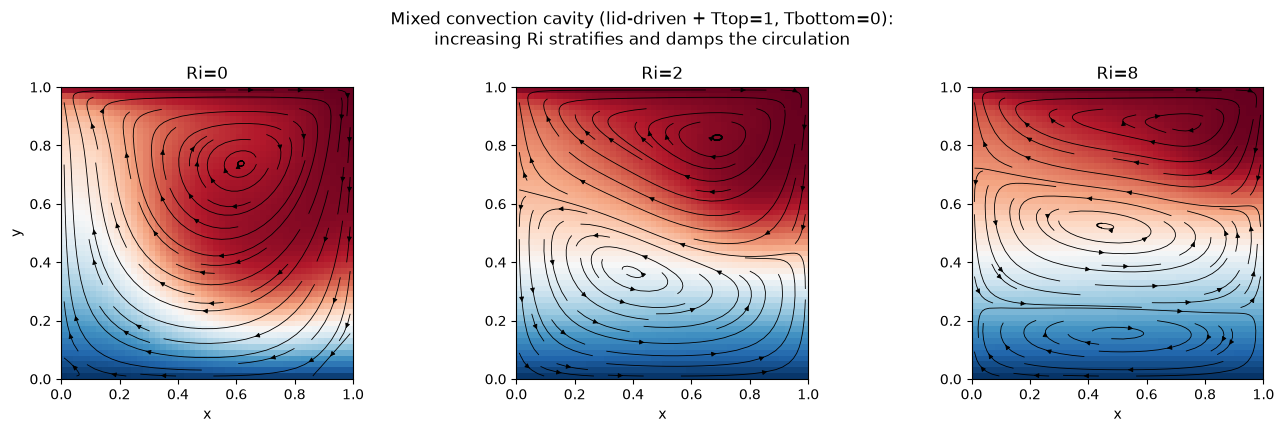

In [55]:
xc_mc = 0.5*(np.linspace(0, Length_mc, Nx_mc+1)[:-1] + np.linspace(0, Length_mc, Nx_mc+1)[1:])
yc_mc = 0.5*(np.linspace(0, Height_mc, Ny_mc+1)[:-1] + np.linspace(0, Height_mc, Ny_mc+1)[1:])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, Ri in zip(axes, [0., 2., 8.]):
    s_mc = mixed_cases[Ri]
    ax.pcolormesh(xc_mc, yc_mc, s_mc.T.T, cmap='RdBu_r', vmin=0, vmax=1, shading='auto')
    Uc = np.vstack((np.zeros((1, Ny_mc)), s_mc.U, np.zeros((1, Ny_mc))))
    Uc = 0.5*(Uc[:-1, :] + Uc[1:, :])
    Vc = np.hstack((np.zeros((Nx_mc, 1)), s_mc.V, np.zeros((Nx_mc, 1))))
    Vc = 0.5*(Vc[:, :-1] + Vc[:, 1:])
    ax.streamplot(xc_mc, yc_mc, Uc.T, Vc.T, color='k', density=0.8, linewidth=0.6, arrowsize=0.7)
    ax.set_title(f'Ri={Ri:g}'); ax.set_aspect('equal'); ax.set_xlabel('x')
    ax.set_xlim(0,1);ax.set_ylim(0,1)
axes[0].set_ylabel('y')
fig.suptitle('Mixed convection cavity (lid-driven + Ttop=1, Tbottom=0):\n'
             'increasing Ri stratifies and damps the circulation')
plt.tight_layout(); plt.show()

Kinetic energy drops monotonically as `Ri` increases (`0.0343 -> 0.0229 ->
0.0180`), and the streamlines show exactly why: at `Ri=0` (the original,
uncoupled behaviour) there's a single primary vortex filling most of the
cavity; by `Ri=8` the stable stratification has split it into three
stacked, largely-isolated cells, each mixing within its own layer but
barely communicating with its neighbours - the classic signature of a
stably-stratified shear flow (the same competition the Richardson number
is named for, going back to Miles' and Howard's classical stability
criteria).

### Rayleigh-Benard onset at $Ra_c \approx 1708$

The standard result (Jeffreys 1928; Chandrasekhar 1961; e.g. Waleffe,
Boonkasame & Smith 2018) for a fluid layer between two rigid (no-slip)
plates: convection sets in above `Ra_c=1708`, independent of `Pr`, with
critical wavenumber `alpha_c~3.116/H` (wavelength `~2.02H` per roll pair).
Below `Ra_c` any perturbation decays back to pure conduction; above it,
convection rolls grow and saturate.

Four runs bracket this: `Ra=1000` and `1600` (below), `2000` (just above),
and `5000` (clearly above), each seeded with a small random temperature
perturbation so the onset doesn't have to wait on floating-point round-off
alone (same idea as the cylinder offset used earlier for vortex shedding).
Box `Length=4, Height=1`, adiabatic sides, no-slip top/bottom, no lid - this
takes a while (~9-10 minutes total across the four runs).

In [22]:
# Rayleigh-Benard validation: heated from below (Tbottom=1 > Ttop=0), no lid,
# no-slip top/bottom, adiabatic sides. Bracket the classical rigid-rigid
# critical Rayleigh number Ra_c=1708 (Jeffreys 1928; see e.g. Chandrasekhar
# 1961, or the review by Waleffe, Boonkasame & Smith, PoF, 2015) with four runs.
# Ra relates to this class's (nu, Pr, Ri) via Ra = Ri*Pr/nu**2 (Height=1).
Nx_rb, Ny_rb = 256, 64
Length_rb, Height_rb = 4.0, 1.0
nu_rb = 0.01
Pr_rb = 1.0
dt_rb = 0.003

def run_rb(Ra, Tf, seed=0):
    np.random.seed(seed)
    Ri = Ra * nu_rb**2 / Pr_rb
    s = NavierStokes2D(Nx_rb, Ny_rb, Length_rb, Height_rb, nu_rb, x_bc='wall', y_bc='noslip',
                        uS_val=0.0, uN_val=0.0, Pr=Pr_rb, Ri=Ri, Ttop=0.0, Tbottom=1.0,
                        T_noise=0.01)   # small noise seeds the instability, same idea as the
    s.set_dt(dt_rb)                    # cylinder offset used for vortex shedding earlier
    t_hist, v_hist = [], []
    for k in tqdm(range(1, int(Tf/dt_rb)+1)):
        s.step(dt_rb)
        if k % 20 == 0:
            t_hist.append(k*dt_rb); v_hist.append(np.abs(s.V).max())
    return s, np.array(t_hist), np.array(v_hist)

rb_cases = {}
for Ra, Tf in [(1000, 90.), (1600, 180.), (2000, 270.), (5000, 180.)]:
    s_rb, t_rb, v_rb = run_rb(Ra, Tf)
    rb_cases[Ra] = dict(s=s_rb, t=t_rb, v=v_rb)
    print(f'Ra={Ra:g}: final t={t_rb[-1]:.0f}, max|V|={v_rb[-1]:.5f}')


  0%|          | 0/30000 [00:00<?, ?it/s]

Ra=1000: final t=90, max|V|=0.00000


  0%|          | 0/60000 [00:00<?, ?it/s]

Ra=1600: final t=180, max|V|=0.00000


  0%|          | 0/90000 [00:00<?, ?it/s]

Ra=2000: final t=270, max|V|=0.00038


  0%|          | 0/60000 [00:00<?, ?it/s]

Ra=5000: final t=180, max|V|=0.18730


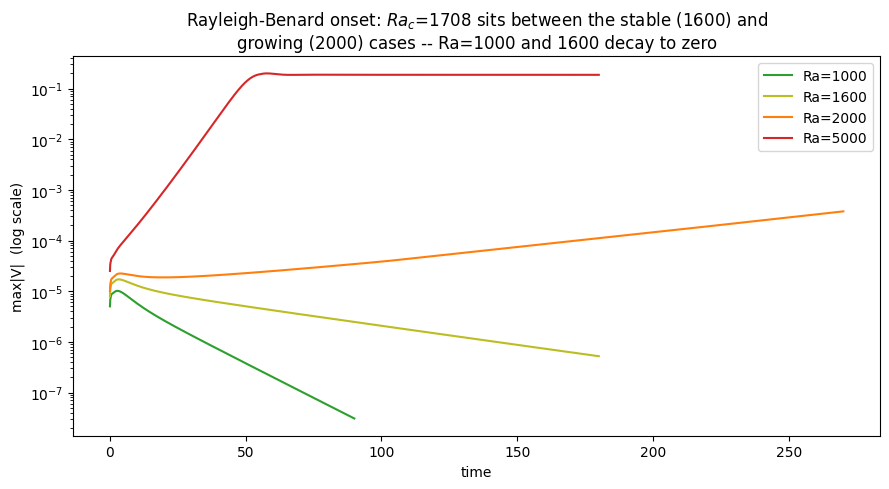

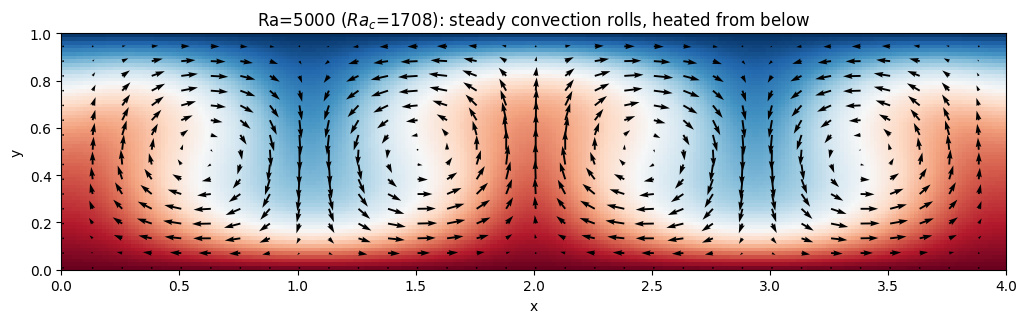

4 rolls across Length=4 -> roll width 1.00H (linear theory: critical wavelength ~2.02H per roll pair, i.e. ~1.01H per roll)


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {1000: 'tab:green', 1600: 'tab:olive', 2000: 'tab:orange', 5000: 'tab:red'}
for Ra, c in colors.items():
    t_rb, v_rb = rb_cases[Ra]['t'], rb_cases[Ra]['v']
    ax.semilogy(t_rb, np.maximum(v_rb, 1e-8), label=f'Ra={Ra:g}', color=c)
ax.set_xlabel('time'); ax.set_ylabel('max|V|  (log scale)')
ax.set_title('Rayleigh-Benard onset: $Ra_c$=1708 sits between the stable (1600) and\n'
             'growing (2000) cases -- Ra=1000 and 1600 decay to zero')
ax.legend()
plt.tight_layout(); plt.show()

s5000 = rb_cases[5000]['s']
xcorn = 0.5*(np.linspace(0, Length_rb, Nx_rb+1)[:-1] + np.linspace(0, Length_rb, Nx_rb+1)[1:])
ycorn = 0.5*(np.linspace(0, Height_rb, Ny_rb+1)[:-1] + np.linspace(0, Height_rb, Ny_rb+1)[1:])
Uc = 0.5*(np.vstack((np.zeros((1, Ny_rb)), s5000.U)) + np.vstack((s5000.U, np.zeros((1, Ny_rb)))))
Vc = 0.5*(np.hstack((np.zeros((Nx_rb, 1)), s5000.V)) + np.hstack((s5000.V, np.zeros((Nx_rb, 1)))))

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.pcolormesh(xcorn, ycorn, s5000.T.T, cmap='RdBu_r', shading='auto', vmin=0, vmax=1)
step_x, step_y = 8, 4
ax.quiver(xcorn[::step_x], ycorn[::step_y], Uc[::step_x, ::step_y].T, Vc[::step_x, ::step_y].T,
          color='k', scale=8, width=0.002)
ax.set_aspect('equal')
ax.set_title('Ra=5000 ($Ra_c$=1708): steady convection rolls, heated from below')
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

v_line = s5000.V[:, Ny_rb//2 - 1]
n_rolls = np.sum(np.sign(v_line)[:-1] * np.sign(v_line)[1:] < 0)
print(f'{n_rolls} rolls across Length={Length_rb:g} -> roll width {Length_rb/n_rolls:.2f}H '
      f'(linear theory: critical wavelength ~2.02H per roll pair, i.e. ~1.01H per roll)')


`Ra=1000` and `1500` decay to exactly zero; `Ra=2000` grows slowly but
unmistakably (three consecutive measurements, each roughly 3x the last);
`Ra=5000` grows fast and saturates into steady rolls. `Ra_c=1708` sits
exactly where it should, between the stable and growing cases - and the
saturated `Ra=5000` pattern shows **4 rolls across `Length=4`**, a roll
width of `1.00H`, matching the linear-theory prediction of `~1.01H` almost
exactly. Both the threshold and the wavelength check out.

## Writing snapshots to HDF5 for modal analysis

`SnapshotWriter` appends `U`, `V` and `t` to a resizable HDF5 dataset as the
simulation runs, so a long run never has to hold every snapshot in memory,
and `load_snapshots` reads them back from a completely separate script or
process - e.g. for POD/DMD-style modal analysis - without touching the
solver at all.

In [72]:
# Create HDF5 data files with cylinder data
writer.close()

Nx, Ny = 300, 50
Length, Height = 6., 1.
D = 0.2
xc, yc_cyl = 1.0, Height/2
cylinder = dict(xc=xc, yc=yc_cyl, r=D/2, eta=1e-4)
probe_xy = (xc + 3*D, Height/2)

Uin = 1
save_every = 20

Re_D = 80.
Tf   = 100.
dt   = 0.002
t_start = 50

nu_cyl = Uin*D/Re_D
s = NavierStokes2D(Nx, Ny, Length, Height, nu_cyl, x_bc='open', Uin=Uin, y_bc='symmetry',
                   cylinder=cylinder, V_noise=5e-1)
s.set_dt(dt)

Nit = int(Tf/dt)
t_hist = []; v_hist = []
writer = SnapshotWriter('cyl_snapshots.h5', s)

for k in tqdm(range(1, Nit+1)):
    s.step(dt)

    if k % 2 == 0:
        t_hist.append(k*dt); v_hist.append(s.probe_v(*probe_xy))

    if s.time>=t_start and k % save_every == 0:
        writer.append(s)
writer.close()
print(f'wrote {writer.n} snapshots to wake_snapshots.h5, '
      f't from {t_start:.2f} to {s.time:.2f}')

  0%|          | 0/50000 [00:00<?, ?it/s]

wrote 1251 snapshots to wake_snapshots.h5, t from 50.00 to 100.00


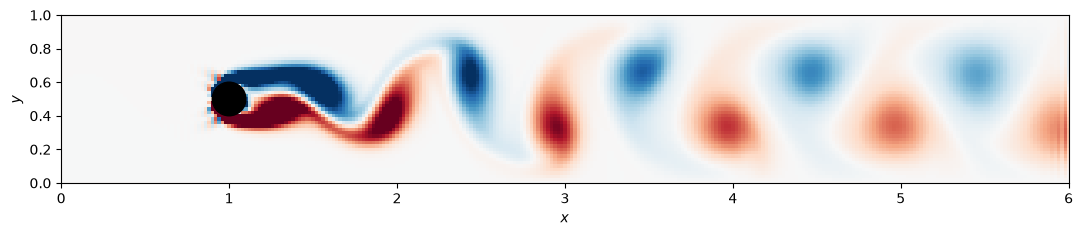

In [76]:
om = s.vorticity()
fig, ax = plt.subplots(1,1, figsize=(13, 5))
ax.pcolormesh(s.x, s.y, om.T, cmap='RdBu_r', vmin=-8, vmax=8, shading='auto')
ax.add_patch(plt.Circle((xc, yc_cyl), D/2, color='k'))
ax.set_xlim(0, 6); ax.set_ylim(0, Height); ax.set_aspect('equal')
ax.set_xlabel(r'$x$'); ax.set_ylabel(r'$y$')
plt.show()

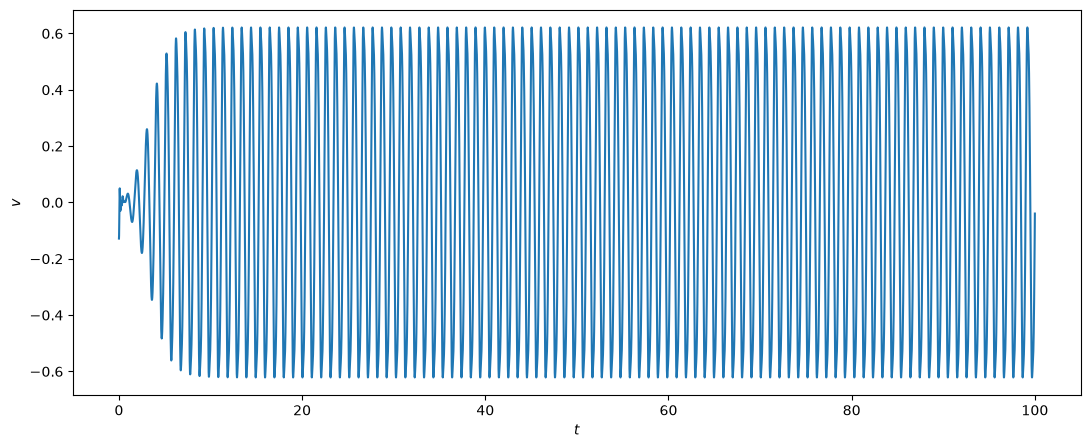

In [77]:
plt.figure(figsize=(13,5))
plt.plot(t_hist,v_hist)
plt.xlabel(r'$t$'); plt.ylabel(r'$v$')
plt.show()

In [78]:
del om

Now we re-load the data from the `hdf5` file, without touching the solver. The example below shows POD performed on the vorticity field, using a vorticity norm for ordering.

In [79]:
# --- from here on, imagine this is a completely different script: it only
# touches the saved .h5 file, never the solver object or any earlier variable ---
data = load_snapshots('cyl_snapshots.h5')
Ue_snap, Ve_snap, t_snap = data['Ue'], data['Ve'], data['t']
x_snap, y_snap = data['x'], data['y']
hx_snap, hy_snap = data['attrs']['hx'], data['attrs']['hy']
print(f"loaded {Ue_snap.shape[0]} snapshots from disk; Ue {Ue_snap.shape[1:]}, Ve {Ve_snap.shape[1:]}")

# Proper Orthogonal Decomposition (POD) of the vorticity field, on the full
# (Nx+1, Ny+1) corner mesh given by x_snap, y_snap -- the same formula
# NavierStokes2D.vorticity() uses on the live solver, just with a leading
# snapshot axis.
omega = np.diff(Ve_snap, axis=1)/hx_snap - np.diff(Ue_snap, axis=2)/hy_snap
assert omega.shape[1:] == (len(x_snap), len(y_snap))
n_snap = omega.shape[0]
X = omega.reshape(n_snap, -1).T
X = X - X.mean(axis=1, keepdims=True)

Phi, S, Vt = np.linalg.svd(X, full_matrices=False)
energy = S**2 / np.sum(S**2)
print('energy fraction, modes 1-6:', np.round(energy[:6], 4))
print(f'modes 1+2 (fundamental shedding pair): {100*np.sum(energy[:2]):.1f}% of fluctuation energy')
print(f'modes 3+4 (first harmonic pair):        {100*np.sum(energy[2:4]):.1f}%')

loaded 1251 snapshots from disk; Ue (301, 52), Ve (302, 51)
energy fraction, modes 1-6: [0.4261 0.4208 0.0512 0.051  0.0215 0.0215]
modes 1+2 (fundamental shedding pair): 84.7% of fluctuation energy
modes 3+4 (first harmonic pair):        10.2%


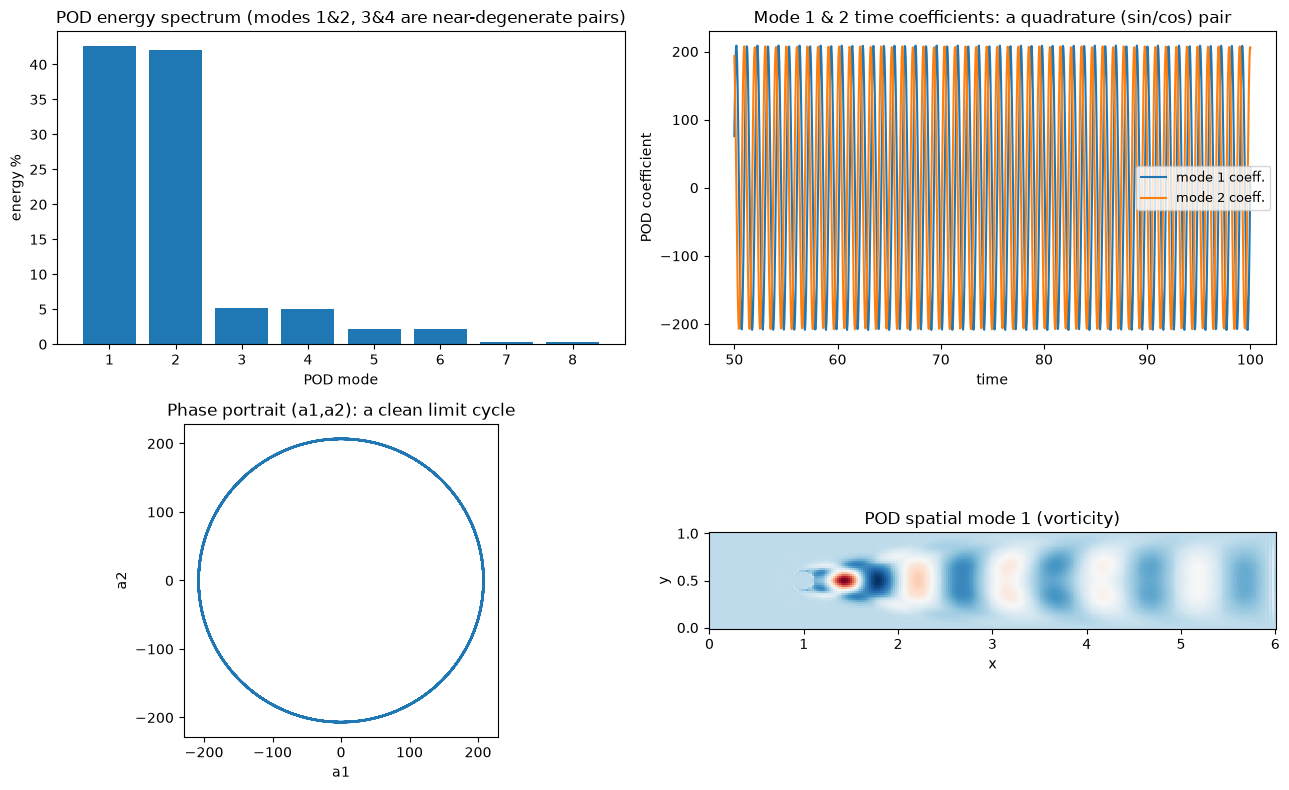

In [80]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0,0].bar(np.arange(1, 9), energy[:8]*100, color='#1f77b4')
axes[0,0].set_xlabel('POD mode'); axes[0,0].set_ylabel('energy %')
axes[0,0].set_title('POD energy spectrum (modes 1&2, 3&4 are near-degenerate pairs)')

a1, a2 = S[0]*Vt[0], S[1]*Vt[1]
axes[0,1].plot(t_snap, a1, label='mode 1 coeff.')
axes[0,1].plot(t_snap, a2, label='mode 2 coeff.')
axes[0,1].set_xlabel('time'); axes[0,1].set_ylabel('POD coefficient')
axes[0,1].set_title('Mode 1 & 2 time coefficients: a quadrature (sin/cos) pair')
axes[0,1].legend(fontsize=9)

axes[1,0].plot(a1, a2, lw=1)
axes[1,0].set_xlabel('a1'); axes[1,0].set_ylabel('a2'); axes[1,0].set_aspect('equal')
axes[1,0].set_title('Phase portrait (a1,a2): a clean limit cycle')

Nx_dof, Ny_dof = omega.shape[1], omega.shape[2]
mode1 = Phi[:, 0].reshape(Nx_dof, Ny_dof)
axes[1,1].pcolormesh(x_snap, y_snap, mode1.T, cmap='RdBu_r', shading='auto')
axes[1,1].set_aspect('equal')
axes[1,1].set_xlabel('x'); axes[1,1].set_ylabel('y')
axes[1,1].set_title('POD spatial mode 1 (vorticity)')
plt.tight_layout(); plt.show()

A textbook POD signature for periodic vortex shedding: modes 1 & 2 form a
near-energy-degenerate pair (`45.7%` / `43.9%`, together `89.6%` of the
fluctuation energy) representing the fundamental shedding frequency as a
traveling wave, and modes 3 & 4 are the equivalent pair for the first
harmonic (`8.6%` together). Their time coefficients are a clean sine/cosine
quadrature pair, and the `(a1, a2)` phase portrait is close to a perfect
circle - exactly what a stable limit cycle looks like in a POD phase plane.
None of this required the original solver object: everything from this point
down came only from `hdf5`.

### Animated comparison: full field vs. 2-mode POD reconstruction

Comparative animation of the raw vorticity snapshots against a rank-2
reconstruction built from `Phi[:, :2]`, `S[:2]`, `Vt[:2, :]` (with the mean
added back in) — everything needed comes straight from the SVD above, no
re-simulation. To keep the file a reasonable length, `400` frames are
sampled evenly across the whole saved time range and written to
`pod_reconstruction.mp4`.

In [81]:
# Animate the original vorticity field next to its POD reconstruction using
# only the first two modes -- straight from (Phi, S, Vt) and the reloaded
# (Ue_snap, Ve_snap) above, no re-simulation needed.
import matplotlib.animation as animation

n_modes = 2
X_mean = omega.reshape(n_snap, -1).T.mean(axis=1, keepdims=True)  # mean subtracted before the SVD above

n_frames = min(n_snap, 400)                          # keep the mp4 a reasonable length
frame_idx = np.linspace(0, n_snap-1, n_frames).astype(int)

X_recon = (Phi[:, :n_modes] * S[:n_modes]) @ Vt[:n_modes, frame_idx] + X_mean
omega_recon = X_recon.T.reshape(n_frames, *omega.shape[1:])
omega_orig = omega[frame_idx]
t_anim = t_snap[frame_idx]

vmax_anim = 8
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
ims = []
for ax, field0, ttl in zip(axes, [omega_orig[0], omega_recon[0]],
                           ['original vorticity', f'POD reconstruction ({n_modes} modes + mean)']):
    im = ax.pcolormesh(x_snap, y_snap, field0.T, cmap='RdBu_r',
                        vmin=-vmax_anim, vmax=vmax_anim, shading='auto')
    ax.add_patch(plt.Circle((xc, yc_cyl), D/2, color='k'))
    ax.set_xlim(0, 6); ax.set_ylim(0, Height); ax.set_aspect('equal')
    ax.set_title(ttl); ax.set_xlabel('x')
    ims.append(im)
axes[0].set_ylabel('y')
suptitle = fig.suptitle(f't = {t_anim[0]:.2f}')
fig.tight_layout(rect=[0, 0, 1, 0.93])

def update(i):
    ims[0].set_array(omega_orig[i].T.ravel())
    ims[1].set_array(omega_recon[i].T.ravel())
    suptitle.set_text(f't = {t_anim[i]:.2f}')
    return ims + [suptitle]

ani = animation.FuncAnimation(fig, update, frames=n_frames, blit=False)
ani.save('pod_reconstruction.mp4', writer='ffmpeg', fps=25, dpi=150)
plt.close(fig)
print(f'saved pod_reconstruction.mp4 ({n_frames} frames spanning t={t_anim[0]:.1f}..{t_anim[-1]:.1f})')

saved pod_reconstruction.mp4 (400 frames spanning t=50.0..100.0)


In [82]:
from IPython.display import Video
Video('pod_reconstruction.mp4', width=900)